In [1]:
import sys, os, glob
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

DATA_DIR = os.path.expanduser("~/dc-allen-data-acquire/data/raw/")
PATH = glob.glob(os.path.join(DATA_DIR, "*709401*.nwb"))[0]
print("File:", os.path.basename(PATH))

io = NWBHDF5IO(PATH, mode="r")
nwb = io.read()

print("Drugs:", nwb.pharmacology)
print("\nAcquisition:", list(nwb.acquisition.keys()))
print("LFP probes:", list(nwb.acquisition["LFP"].electrical_series.keys()))

trials = nwb.trials.to_dataframe()
print("\nStates:")
print(trials.groupby("behavioral_epoch").agg(start=("start_time", "min"), stop=("stop_time", "max")))

elec = nwb.acquisition["LFP"]["ElectricalSeriesprobeF"].electrodes.to_dataframe()
print("\nprobeF regions:", sorted(set(elec.location)))

File: 709401-20231213-v001.nwb
Drugs: isoflurane (inhalation): induction at 5%, maintenance at 1.5%

Acquisition: ['ElectricalSeriesEEG', 'LFP', 'isoflurane_level']
LFP probes: ['ElectricalSeriesprobeB', 'ElectricalSeriesprobeC', 'ElectricalSeriesprobeD', 'ElectricalSeriesprobeF']

States:
                       start       stop
behavioral_epoch                       
awake              758.05193  3069.4437
isoflurane        4767.79760  7079.9113

probeF regions: ['ACAd6a', 'LSr', 'MOs1', 'MOs2/3', 'MOs5', 'MOs6a', 'MS', 'PL6a', 'PL6b', 'SEZ', 'STR', 'ccg', 'cing', 'fa', 'null']


[prep] 709401-20231213-v001.nwb: isoflurane, probeF MOs5 channel 304, 7306 s at 250.0 Hz (4s)
  [real data] 5274 timepoints, candidates per threshold: [10, 13, 18, 32, 37] (0.3s)
  [null 1/20] 6678 timepoints, candidates per threshold: [8, 17, 29, 41, 58] (0.4s)
  [null 2/20] 6642 timepoints, candidates per threshold: [9, 16, 32, 41, 58] (0.4s)
  [null 3/20] 6666 timepoints, candidates per threshold: [16, 19, 32, 42, 59] (0.4s)
  [null 4/20] 6611 timepoints, candidates per threshold: [6, 10, 36, 48, 60] (0.4s)
  [null 5/20] 6627 timepoints, candidates per threshold: [10, 14, 32, 46, 57] (0.4s)
  [null 6/20] 6679 timepoints, candidates per threshold: [11, 20, 30, 44, 58] (0.4s)
  [null 7/20] 6672 timepoints, candidates per threshold: [12, 20, 31, 45, 55] (0.4s)
  [null 8/20] 6670 timepoints, candidates per threshold: [12, 15, 30, 43, 57] (0.4s)
  [null 9/20] 6670 timepoints, candidates per threshold: [11, 16, 29, 47, 60] (0.5s)
  [null 10/20] 6622 timepoints, candidates per threshold: [

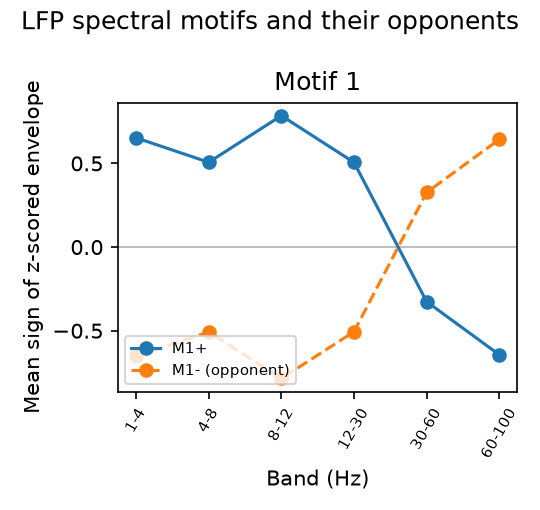

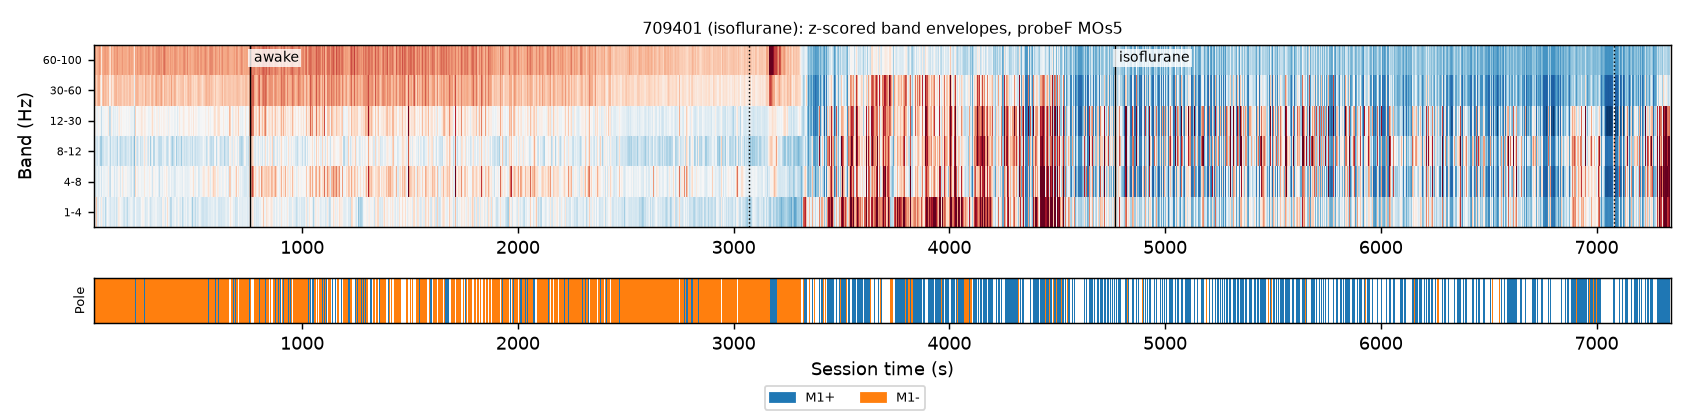

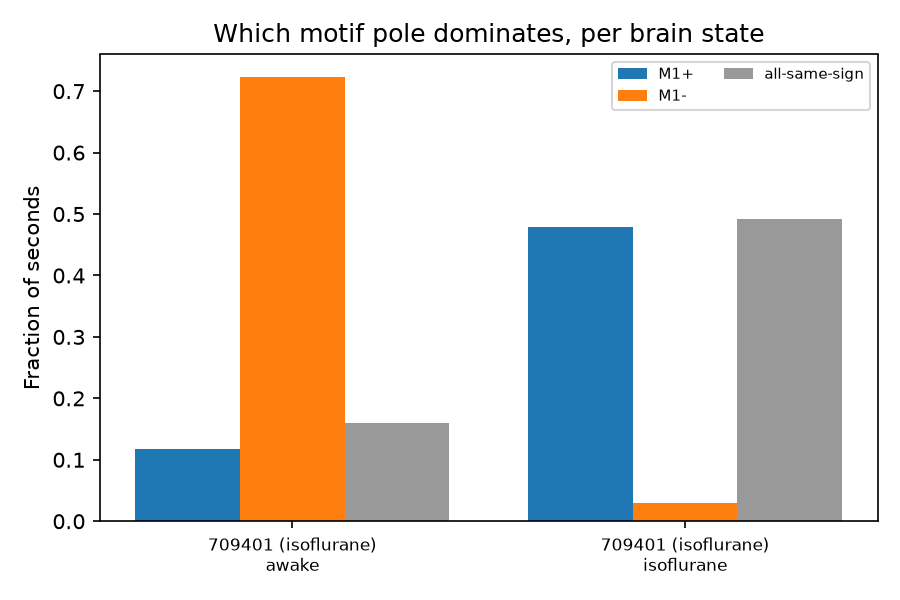

In [2]:
import os, sys, types
src_dir = os.path.abspath("../src")
mapping = types.ModuleType("src.mapping")
mapping.__path__ = [src_dir]
sys.modules["src.mapping"] = mapping

from pathlib import Path
from IPython.display import Image, display
from src.mapping.lfp_to_motifs import prepare, find_motifs, write_outputs
from src.mapping.smooth_env import DEFAULT_FREQ_BANDS
%matplotlib inline

# Load one MOs5 channel, find motifs, save results
prep_lfp = prepare([PATH], "probeF", "MOs5", 250.0, DEFAULT_FREQ_BANDS)
run_lfp = find_motifs(prep_lfp, n_null=20, seed=0)

OUT_LFP = Path("results/709401_jahan/lfp")
write_outputs(run_lfp, OUT_LFP)

# Print % of time in each motif, per state
for row in run_lfp["table"]:
    top = sorted(row["fraction"].items(), key=lambda kv: -kv[1])[:4]
    print(row["state"], ":", ", ".join(f"{k} {v:.0%}" for k, v in top))

# Show the plots
for name in ["motifs.png", "timeline.png", "occupancy.png"]:
    if (OUT_LFP / name).exists():
        display(Image(str(OUT_LFP / name)))

In [3]:
eeg = nwb.acquisition["ElectricalSeriesEEG"]
print("Shape (time, channels):", eeg.data.shape)
print("Rate:", eeg.rate, "| Has timestamps:", eeg.timestamps is not None)
print("Conversion:", eeg.conversion, "| Unit:", eeg.unit)

eeg_elec = eeg.electrodes.to_dataframe()
print(eeg_elec[["location", "is_data_valid"]])

Shape (time, channels): (18316288, 30)
Rate: None | Has timestamps: True
Conversion: 1.949999928474426e-07 | Unit: volts
   location  is_data_valid
id                        
0      VISl           True
1      VISp           True
2    RSPagl           True
3     VISal          False
4      VISp           True
5    RSPagl           True
6   SSp-bfd           True
7      VISa           True
8    RSPagl           True
9   SSp-bfd           True
10   SSp-ll           True
11      MOp           True
12      MOs           True
13      MOs           True
14      MOs           True
15      MOs           True
16      MOs           True
17      MOs           True
18      MOp           True
19   SSp-ll           True
20  SSp-bfd           True
21   RSPagl           True
22     VISa           True
23  SSp-bfd           True
24   RSPagl           True
25     VISp           True
26    VISal           True
27   RSPagl           True
28     VISp           True
29     VISl           True


[prep] EEG ch 13 (MOs): 7306 s at 250.0 Hz
[motifs] EEG ch13 MOs seed 0: 0 motif pair(s) (9s)

EEG ch 13:
   awake : all-same-sign 100%
   isoflurane : all-same-sign 100%


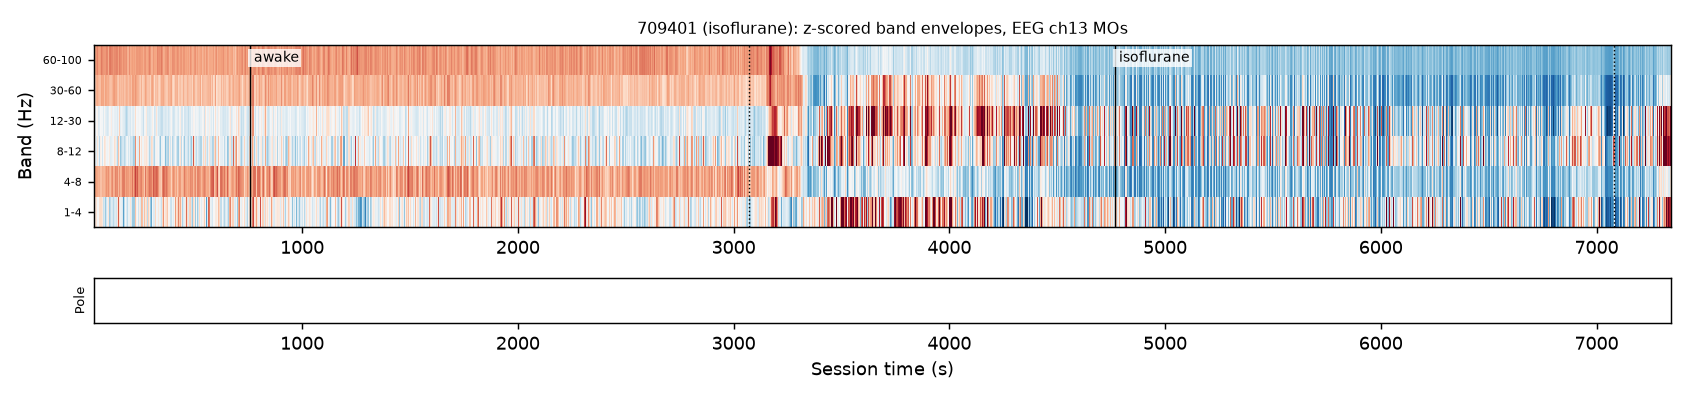

[prep] EEG ch 9 (SSp-bfd): 7306 s at 250.0 Hz
[motifs] EEG ch9 SSp-bfd seed 0: 0 motif pair(s) (9s)

EEG ch 9:
   awake : all-same-sign 100%
   isoflurane : all-same-sign 100%


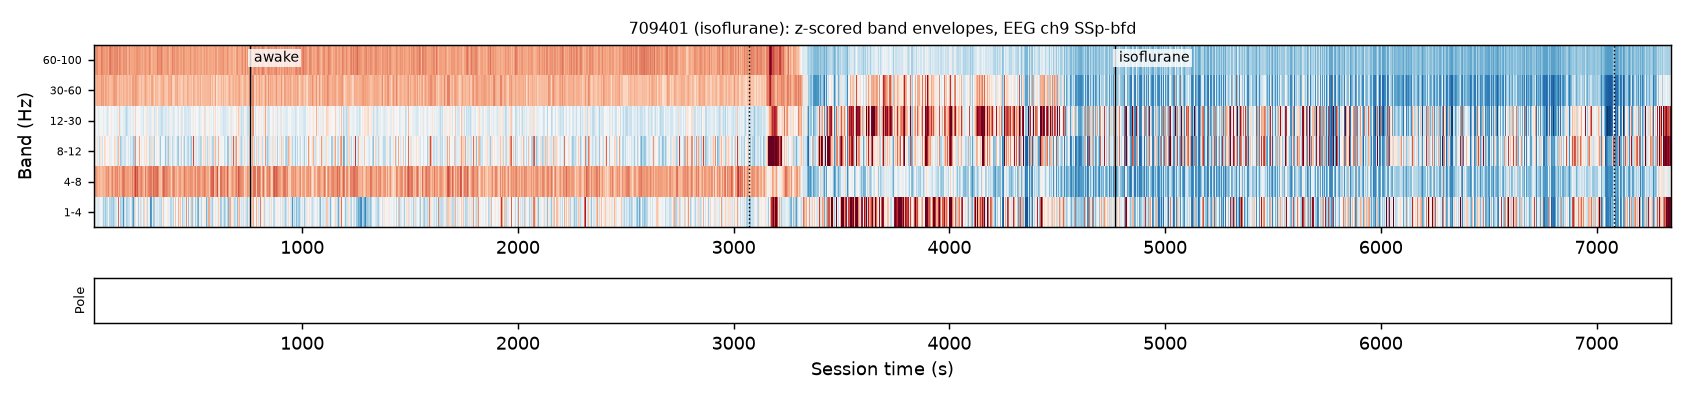

EEG ch 13: no motif to compare
EEG ch 9: no motif to compare


In [4]:
from scipy import signal
from src.mapping.smooth_env import smooth_env, mround

trials = nwb.trials.to_dataframe()
STATES = sorted(
    [(str(k), float(g.start_time.min()), float(g.stop_time.max()))
     for k, g in trials.groupby("behavioral_epoch")],
    key=lambda s: s[1],
)

def prep_eeg(ch, target_fs=250.0):
    s = nwb.acquisition["ElectricalSeriesEEG"]
    ts = s.timestamps[:]
    fs_raw = 1 / np.median(np.diff(ts[:100_000]))
    raw = s.data[:, ch] * s.conversion * 1e6          # microvolts
    b, a = signal.iirnotch(60, 30, fs_raw)              # remove 60 Hz line noise
    raw = signal.filtfilt(b, a, raw)
    q = mround(fs_raw / target_fs)
    x, t, fs = signal.decimate(raw, q, zero_phase=True), ts[::q], fs_raw / q
    env = smooth_env(x, fs, DEFAULT_FREQ_BANDS)
    ok = np.isfinite(env).all(axis=1)
    loc = s.electrodes.to_dataframe().location.iloc[ch]
    session = {
        "file": os.path.basename(PATH), "subject": nwb.subject.subject_id,
        "experiment": "isoflurane", "pharmacology": nwb.pharmacology,
        "states": STATES, "probe": "EEG", "region": f"ch{ch} {loc}",
        "channel": ch, "electrode_id": ch, "fs": fs, "t": t[ok],
    }
    print(f"[prep] EEG ch {ch} ({loc}): {ok.sum() / fs:.0f} s at {fs:.1f} Hz")
    return {"sessions": [session], "envelopes": [env[ok]], "bands": DEFAULT_FREQ_BANDS,
            "probe": "EEG", "region": f"ch{ch} {loc}", "fs": fs}

run_eeg = {}
for ch in [13, 9]:
    run_eeg[ch] = find_motifs(prep_eeg(ch), n_null=20, seed=0, verbose=False)
    out = Path(f"results/709401_jahan/eeg_ch{ch}")
    write_outputs(run_eeg[ch], out)
    print(f"\nEEG ch {ch}:")
    for row in run_eeg[ch]["table"]:
        top = sorted(row["fraction"].items(), key=lambda kv: -kv[1])[:4]
        print("  ", row["state"], ":", ", ".join(f"{k} {v:.0%}" for k, v in top))
    for name in ["motifs.png", "timeline.png", "occupancy.png"]:
        if (out / name).exists():
            display(Image(str(out / name)))

# Compare EEG motif shape to the LFP motif
lfp_m = run_lfp["result"].motifs
for ch, r in run_eeg.items():
    m = r["result"].motifs
    if m.shape[1] and lfp_m.shape[1]:
        corr = np.corrcoef(m[:, 0], lfp_m[:, 0])[0, 1]
        print(f"EEG ch {ch} M1+ vs LFP M1+: correlation = {corr:.2f}")
    else:
        print(f"EEG ch {ch}: no motif to compare")

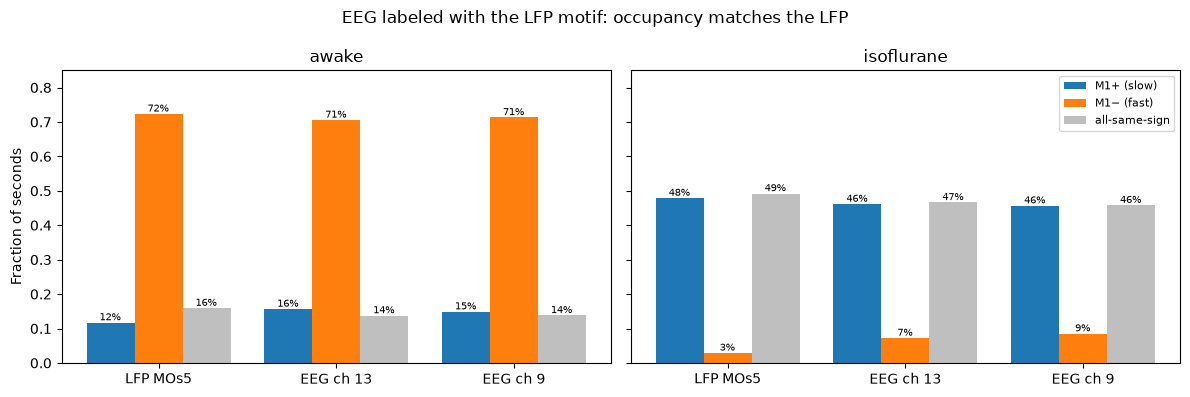

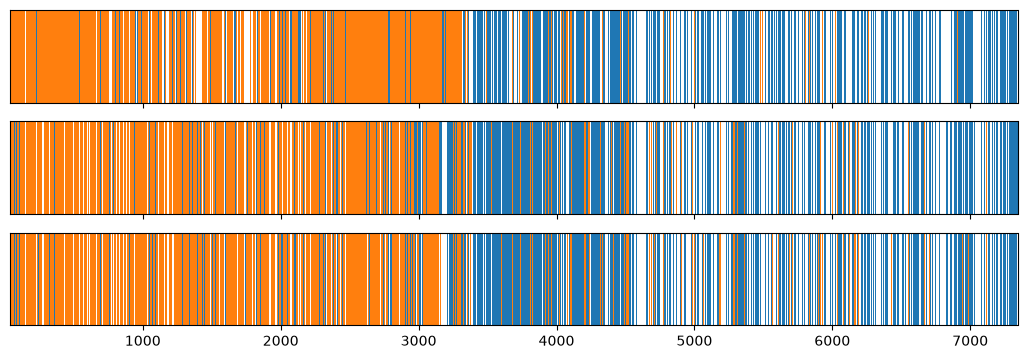

In [5]:
import matplotlib.colors as mcolors

motif = run_lfp["result"].motifs          # LFP M1+ / M1-
POLES = [(0, "M1+ (slow)", "C0"), (1, "M1− (fast)", "C1"), (-1, "all-same-sign", "0.75")]

def label_with_lfp_motif(env_1hz):
    signs = np.sign(env_1hz)
    nontrivial = np.abs(signs.sum(axis=1)) != signs.shape[1]
    pole = np.full(len(signs), -1)
    pole[nontrivial] = np.argmax(signs[nontrivial] @ motif, axis=1)
    return pole

# pole labels, state labels, and times for each signal
signals = {"LFP MOs5": (run_lfp["pole_of"], run_lfp["state_of"], run_lfp["t_1hz"])}
for ch, r in run_eeg.items():
    signals[f"EEG ch {ch}"] = (label_with_lfp_motif(r["env_1hz"]), r["state_of"], r["t_1hz"])

# --- Figure 1: occupancy side by side ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
x = np.arange(len(signals))
width = 0.27
for ax, state in zip(axes, ["awake", "isoflurane"]):
    for k, (code, name, color) in enumerate(POLES):
        vals = [np.mean(p[s == state] == code) for p, s, _ in signals.values()]
        bars = ax.bar(x + (k - 1) * width, vals, width, color=color, label=name)
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=7)
    ax.set_xticks(x, signals.keys())
    ax.set_title(state)
    ax.set_ylim(0, 0.85)
axes[0].set_ylabel("Fraction of seconds")
axes[1].legend(fontsize=8)
fig.suptitle("EEG labeled with the LFP motif: occupancy matches the LFP")
plt.tight_layout()
plt.savefig("results/709401_jahan/eeg_vs_lfp_occupancy.png", dpi=150)
plt.show()

# --- Figure 2: pole strips over the whole session ---
fig, axes = plt.subplots(len(signals), 1, figsize=(13, 1.1 * len(signals) + 0.8), sharex=True)
for ax, (name, (pole, _, t)) in zip(axes, signals.items()):
    rgb = np.ones((1, len(pole), 3))
    for code, _, color in POLES:
        rgb[0, pole == code] = mcolors.to_rgb(color if code != -1 else "white")
    ax.imshow(rgb, aspect="auto", extent=[t[0], t[-1], 0, 1], interpolation="none")
    ax.set_yticks([])

EEG did not yield a motif on its own, but when EEG seconds were labeled with the LFP-derived motif, occupancy closely matched the LFP (awake: 71% vs. 72% fast pole; isoflurane: 46% vs. 48% slow pole). The motif is present in surface EEG; the detection step, not the signal, is the limitation under the current 6-band configuration.

[motifs] probeF MOs5 (awake only) seed 0: 0 motif pair(s) (1s)
[motifs] probeF MOs5 (isoflurane only) seed 0: 0 motif pair(s) (2s)
[motifs] EEG ch13 MOs (awake only) seed 0: 1 motif pair(s) (1s)
[motifs] EEG ch13 MOs (isoflurane only) seed 0: 1 motif pair(s) (1s)
[motifs] EEG ch9 SSp-bfd (awake only) seed 0: 1 motif pair(s) (1s)
[motifs] EEG ch9 SSp-bfd (isoflurane only) seed 0: 1 motif pair(s) (1s)


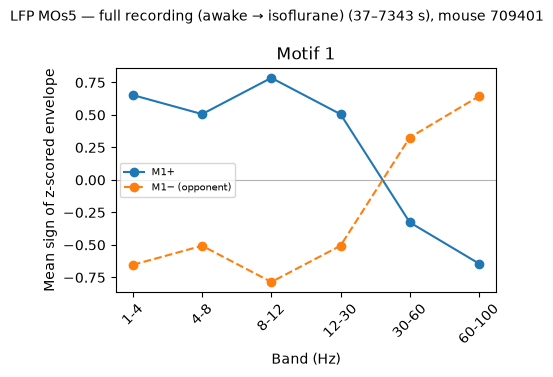

LFP MOs5 — AWAKE only (758–3069 s), mouse 709401: no motif survived the null test
LFP MOs5 — ISOFLURANE only (4768–7080 s), mouse 709401: no motif survived the null test
EEG ch 13 (MOs) — full recording (awake → isoflurane) (37–7343 s), mouse 709401: no motif survived the null test


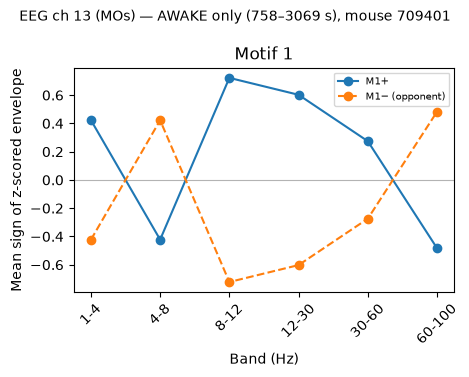

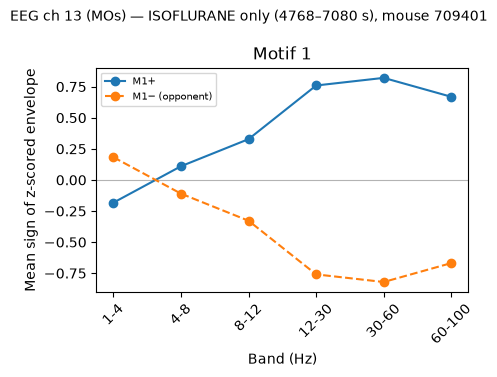

EEG ch 9 (SSp-bfd) — full recording (awake → isoflurane) (37–7343 s), mouse 709401: no motif survived the null test


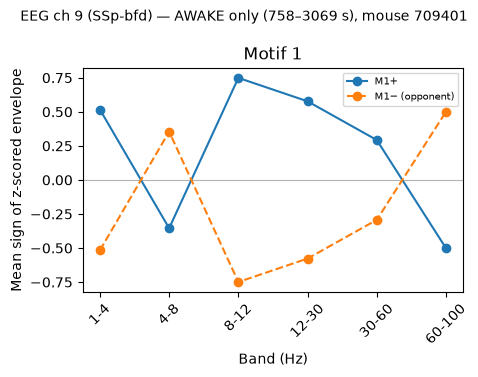

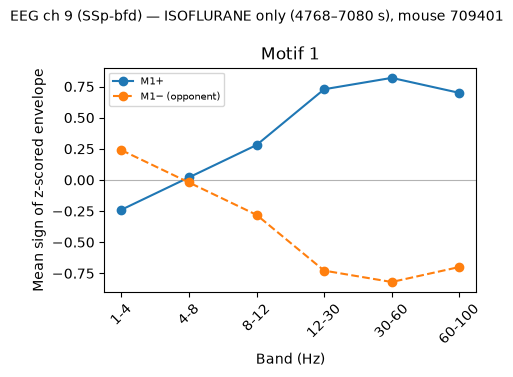


Motif pairs found:
window              awake  isoflurane  full
signal                                     
EEG ch 13 (MOs)         1           1     0
EEG ch 9 (SSp-bfd)      1           1     0
LFP MOs5                0           0     1

How close each run came (largest real group − largest null group, best threshold):
  LFP MOs5             full       : +291 s
  LFP MOs5             awake      : -43 s
  LFP MOs5             isoflurane : -21 s
  EEG ch 13 (MOs)      full       : -241 s
  EEG ch 13 (MOs)      awake      : +443 s
  EEG ch 13 (MOs)      isoflurane : +80 s
  EEG ch 9 (SSp-bfd)   full       : -230 s
  EEG ch 9 (SSp-bfd)   awake      : +457 s
  EEG ch 9 (SSp-bfd)   isoflurane : +51 s


In [6]:
import pandas as pd
from src.mapping.lfp_to_motifs import pole_color

BAND_LABELS = [f"{lo:g}-{hi:g}" for lo, hi in DEFAULT_FREQ_BANDS]
WINDOW_TEXT = {
    "full": "full recording (awake → isoflurane)",
    "awake": "AWAKE only",
    "isoflurane": "ISOFLURANE only",
}

def slice_state(run, state):
    """Keep only one state's seconds and re-z-score the envelopes within it."""
    s0 = run["sessions"][0]
    env, t = run["envelopes"][0], s0["t"]
    start, stop = next((a, b) for name, a, b in s0["states"] if name == state)
    keep = (t >= start) & (t <= stop)
    e = env[keep]
    e = (e - e.mean(axis=0)) / e.std(axis=0)
    region = f"{s0['region']} ({state} only)"
    session = {**s0, "t": t[keep], "states": [(state, start, stop)], "region": region}
    return {"sessions": [session], "envelopes": [e], "bands": run["bands"],
            "probe": run["probe"], "region": region, "fs": run["fs"]}

def plot_motif(run, signal_name, window, path):
    res = run["result"]
    t = run["sessions"][0]["t"]
    title = f"{signal_name} — {WINDOW_TEXT[window]} ({t[0]:.0f}–{t[-1]:.0f} s), mouse 709401"
    n = res.n_motifs
    if n == 0:
        print(f"{title}: no motif survived the null test")
        return
    fig, axes = plt.subplots(1, n, figsize=(4.8 * n, 3.8), squeeze=False, sharey=True)
    for i, ax in enumerate(axes[0]):
        ax.axhline(0, color="0.7", lw=0.8)
        ax.plot(BAND_LABELS, res.motifs[:, i], "-o", color=pole_color(i, n), label=f"M{i+1}+")
        ax.plot(BAND_LABELS, res.motifs[:, i + n], "--o", color=pole_color(i + n, n), label=f"M{i+1}− (opponent)")
        ax.set_title(f"Motif {i+1}")
        ax.set_xlabel("Band (Hz)")
        ax.tick_params(axis="x", rotation=45)
        ax.legend(fontsize=7)
    axes[0][0].set_ylabel("Mean sign of z-scored envelope")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()

full_runs = {"LFP MOs5": run_lfp, "EEG ch 13 (MOs)": run_eeg[13], "EEG ch 9 (SSp-bfd)": run_eeg[9]}
all_runs, rows = {}, []

for name, run in full_runs.items():
    all_runs[(name, "full")] = run
    for state in ["awake", "isoflurane"]:
        all_runs[(name, state)] = find_motifs(slice_state(run, state), n_null=20, seed=0, verbose=False)

for (name, window), run in all_runs.items():
    out = Path(f"results/709401_jahan/{name.split(' (')[0].replace(' ', '_')}_{window}")
    write_outputs(run, out)                      # saves the team's files (summary.json etc.)
    plot_motif(run, name, window, out / "motif_titled.png")
    rows.append({"signal": name, "window": window, "motif pairs": run["result"].n_motifs})

summary = pd.DataFrame(rows).pivot(index="signal", columns="window", values="motif pairs")
print("\nMotif pairs found:")
print(summary[["awake", "isoflurane", "full"]])

print("\nHow close each run came (largest real group − largest null group, best threshold):")
for (name, window), run in all_runs.items():
    res = run["result"]
    best = max(int(s.max()) - int(nm) for s, nm in zip(res.candidate_sizes, res.null_max_size))
    print(f"  {name:20s} {window:11s}: {best:+d} s")

In [7]:
rs = nwb.processing["behavior"]["BehavioralTimeSeries"]["running_speed"]
speed = rs.data[:]
t_speed = rs.timestamps[:] if rs.timestamps is not None else np.arange(len(speed)) / rs.rate + rs.starting_time

for name in ["EEG ch 13 (MOs)", "LFP MOs5"]:
    r = all_runs[(name, "awake")]
    if r["result"].n_motifs == 0:
        print(f"{name}: no awake motif")
        continue
    t1 = r["t_1hz"]
    sp = np.interp(t1, t_speed, speed)
    pole = r["pole_of"]
    print(f"\n{name}, awake only:")
    for code, label in [(0, "M1+"), (1, "M1-"), (-1, "all-same-sign")]:
        pick = pole == code
        print(f"  {label:14s}: {pick.mean():4.0%} of seconds | median running speed {np.median(sp[pick]):5.1f} cm/s")


EEG ch 13 (MOs), awake only:
  M1+           :  42% of seconds | median running speed   7.0 cm/s
  M1-           :  53% of seconds | median running speed  11.1 cm/s
  all-same-sign :   5% of seconds | median running speed  11.2 cm/s
LFP MOs5: no awake motif


M1− (theta + high gamma up): median running speed 11.1 cm/s. 

M1+ (delta + alpha/beta up): median running speed 7.0 cm/s

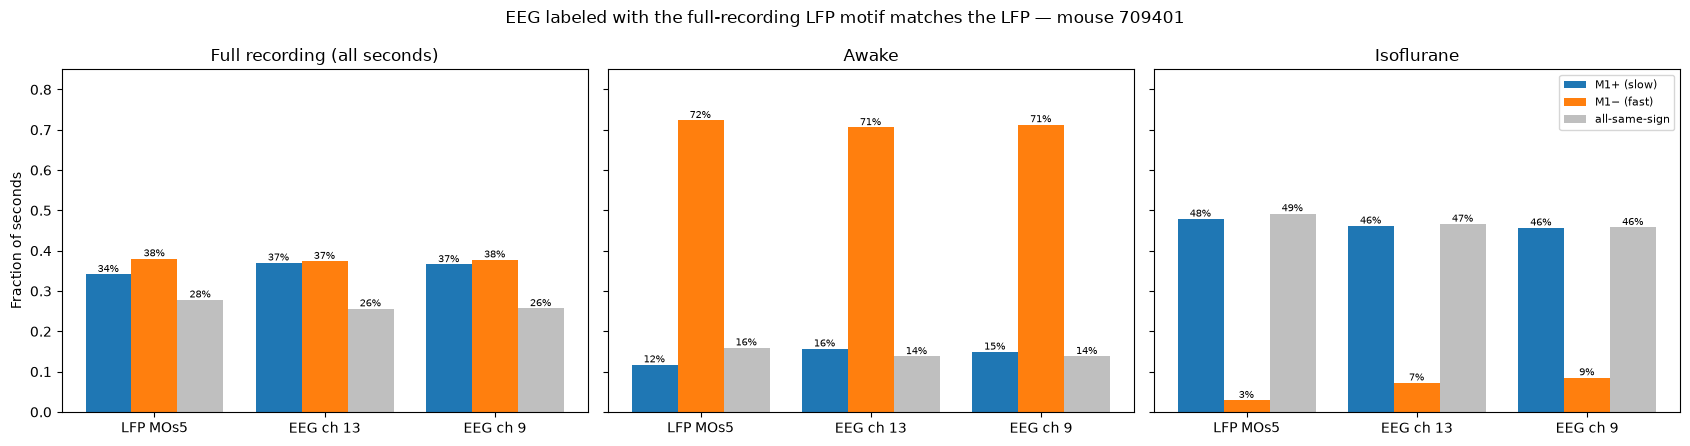

In [8]:
import matplotlib.colors as mcolors

motif = run_lfp["result"].motifs          # full-recording LFP motif (M1+ / M1-)
POLES = [(0, "M1+ (slow)", "C0"), (1, "M1− (fast)", "C1"), (-1, "all-same-sign", "0.75")]

def label_with_lfp_motif(env_1hz):
    signs = np.sign(env_1hz)
    nontrivial = np.abs(signs.sum(axis=1)) != signs.shape[1]
    pole = np.full(len(signs), -1)
    pole[nontrivial] = np.argmax(signs[nontrivial] @ motif, axis=1)
    return pole

signals = {"LFP MOs5": (run_lfp["pole_of"], run_lfp["state_of"])}
for ch, r in run_eeg.items():
    signals[f"EEG ch {ch}"] = (label_with_lfp_motif(r["env_1hz"]), r["state_of"])

PANELS = [
    ("Full recording (all seconds)", None),
    ("Awake", "awake"),
    ("Isoflurane", "isoflurane"),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
x = np.arange(len(signals))
width = 0.27
for ax, (title, state) in zip(axes, PANELS):
    for k, (code, name, color) in enumerate(POLES):
        vals = []
        for pole, state_of in signals.values():
            pick = np.ones(len(pole), bool) if state is None else (state_of == state)
            vals.append(np.mean(pole[pick] == code))
        bars = ax.bar(x + (k - 1) * width, vals, width, color=color, label=name)
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], fontsize=7)
    ax.set_xticks(x, signals.keys())
    ax.set_title(title)
    ax.set_ylim(0, 0.85)
axes[0].set_ylabel("Fraction of seconds")
axes[-1].legend(fontsize=8)
fig.suptitle("EEG labeled with the full-recording LFP motif matches the LFP — mouse 709401")
plt.tight_layout()
plt.savefig("results/709401_jahan/eeg_vs_lfp_occupancy_all.png", dpi=150)
plt.show()

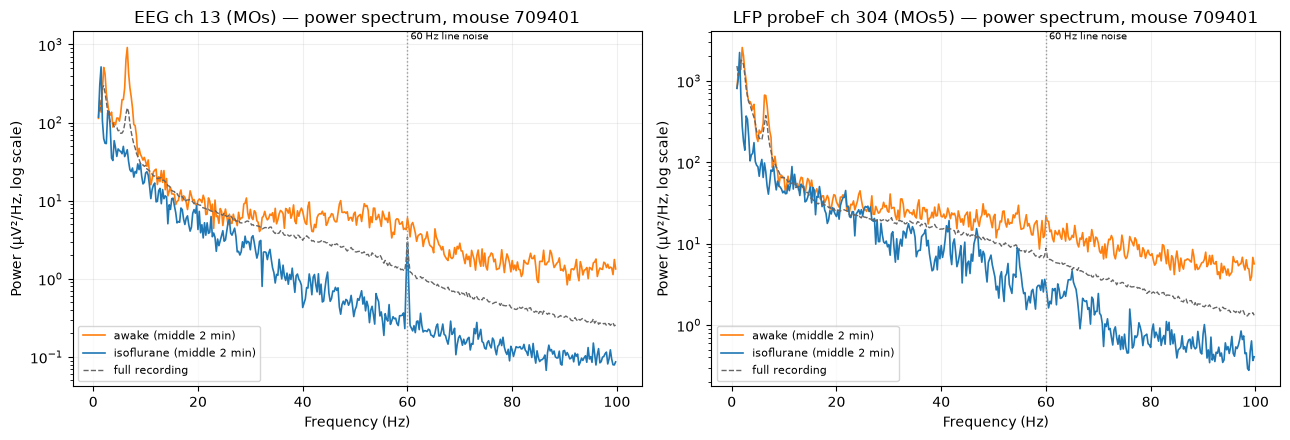

In [9]:
from scipy import signal

_ts_cache = {}
def load_window(series, ch, start, stop):
    key = id(series)
    if key not in _ts_cache:
        _ts_cache[key] = series.timestamps[:]
    ts = _ts_cache[key]
    i0, i1 = np.searchsorted(ts, [start, stop])
    fs = 1 / np.median(np.diff(ts[i0:i0 + 10_000]))
    x = series.data[i0:i1, ch] * series.conversion * 1e6   # microvolts
    return x - np.median(x), fs

def middle(start, stop, dur=120):
    mid = (start + stop) / 2
    return mid - dur / 2, mid + dur / 2

state_bounds = {name: (a, b) for name, a, b in STATES}
PSD_WINDOWS = {
    "awake (middle 2 min)": middle(*state_bounds["awake"]),
    "isoflurane (middle 2 min)": middle(*state_bounds["isoflurane"]),
    "full recording": (state_bounds["awake"][0], state_bounds["isoflurane"][1]),
}
COLORS = {"awake (middle 2 min)": "C1", "isoflurane (middle 2 min)": "C0", "full recording": "0.4"}

eeg_series = nwb.acquisition["ElectricalSeriesEEG"]
lfp_series = nwb.acquisition["LFP"]["ElectricalSeriesprobeF"]
lfp_ch = run_lfp["sessions"][0]["channel"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (series, ch, label) in zip(axes, [(eeg_series, 13, "EEG ch 13 (MOs)"),
                                         (lfp_series, lfp_ch, f"LFP probeF ch {lfp_ch} (MOs5)")]):
    for wname, (start, stop) in PSD_WINDOWS.items():
        x, fs = load_window(series, ch, start, stop)
        f, p = signal.welch(x, fs=fs, nperseg=int(4 * fs), noverlap=int(2 * fs), average="median")
        keep = (f >= 1) & (f <= 100)
        ax.semilogy(f[keep], p[keep], color=COLORS[wname], label=wname,
                    lw=1.2 if wname != "full recording" else 1.0,
                    ls="-" if wname != "full recording" else "--")
    ax.axvline(60, color="0.6", ls=":", lw=1)
    ax.text(60, ax.get_ylim()[1], " 60 Hz line noise", fontsize=7, va="top")
    ax.set_title(f"{label} — power spectrum, mouse 709401")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power (µV²/Hz, log scale)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/709401_jahan/power_spectra_eeg_lfp.png", dpi=150)
plt.show()

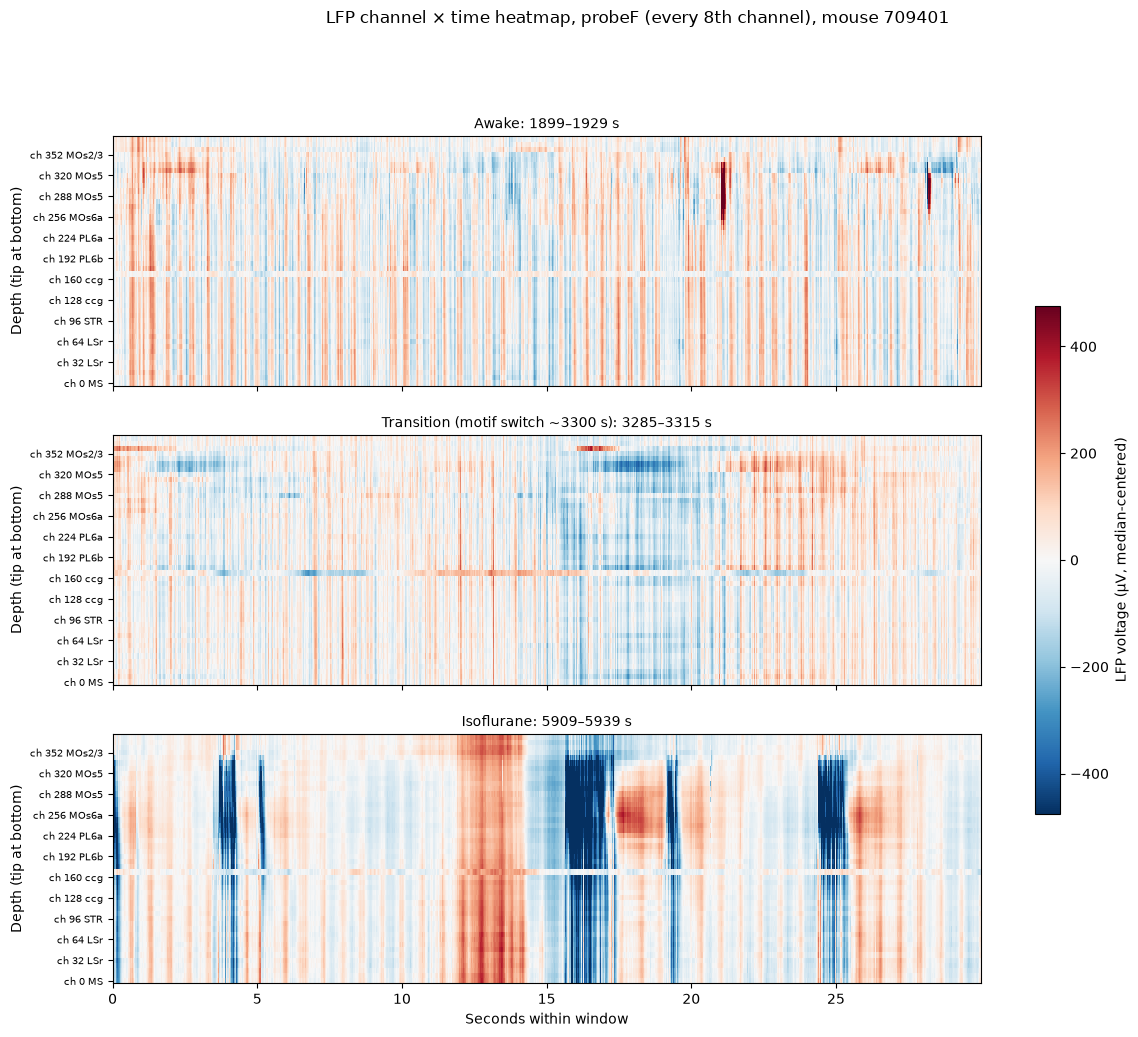

In [10]:
from src.mapping.smooth_env import mround

def load_block(series, start, stop, step=8, target_fs=250):
    """All-depth LFP block: every `step`-th channel, downsampled, in µV."""
    key = id(series)
    if key not in _ts_cache:
        _ts_cache[key] = series.timestamps[:]
    ts = _ts_cache[key]
    i0, i1 = np.searchsorted(ts, [start, stop])
    fs = 1 / np.median(np.diff(ts[i0:i0 + 10_000]))
    x = series.data[i0:i1, ::step] * series.conversion * 1e6
    q = mround(fs / target_fs)
    x = signal.decimate(x, q, axis=0, zero_phase=True)
    return x - np.median(x, axis=0), fs / q

STEP = 8
locs = lfp_series.electrodes.to_dataframe().location.values[::STEP]
chans = np.arange(0, 384, STEP)

HEAT_WINDOWS = {
    "Awake": middle(*state_bounds["awake"], dur=30),
    "Transition (motif switch ~3300 s)": (3285, 3315),
    "Isoflurane": middle(*state_bounds["isoflurane"], dur=30),
}

blocks = {name: load_block(lfp_series, a, b, STEP) for name, (a, b) in HEAT_WINDOWS.items()}
limit = np.percentile(np.abs(np.concatenate([x.ravel() for x, _ in blocks.values()])), 99)

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, (name, (x, fs)) in zip(axes, blocks.items()):
    start, stop = HEAT_WINDOWS[name]
    im = ax.imshow(x.T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit,
                   extent=[0, x.shape[0] / fs, -0.5, len(chans) - 0.5], interpolation="none")
    ticks = np.arange(0, len(chans), 4)
    ax.set_yticks(ticks, [f"ch {chans[i]} {locs[i]}" for i in ticks], fontsize=7)
    ax.set_ylabel("Depth (tip at bottom)")
    ax.set_title(f"{name}: {start:.0f}–{stop:.0f} s", fontsize=10)
axes[-1].set_xlabel("Seconds within window")
fig.colorbar(im, ax=axes, label="LFP voltage (µV, median-centered)", shrink=0.6)
fig.suptitle(f"LFP channel × time heatmap, probeF (every {STEP}th channel), mouse 709401", y=0.995)
plt.savefig("results/709401_jahan/lfp_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

LFP MOs5: BIC chose 8 clusters on real data, 8 on shifted (chance) data
Median assignment confidence: 95% (seconds below 60% confidence: 7%)

Cluster 0: corr with LFP M1+ = +0.97 | awake 0% | iso 5%  
Cluster 1: corr with LFP M1+ = +0.97 | awake 0% | iso 38%  
Cluster 2: corr with LFP M1+ = +0.76 | awake 0% | iso 0%  
Cluster 3: corr with LFP M1+ = +0.89 | awake 0% | iso 35%  ALL BANDS DOWN
Cluster 4: corr with LFP M1+ = -0.07 | awake 0% | iso 22%  ALL BANDS DOWN
Cluster 5: corr with LFP M1+ = -0.97 | awake 54% | iso 0%  
Cluster 6: corr with LFP M1+ = -0.88 | awake 3% | iso 0%  
Cluster 7: corr with LFP M1+ = -1.00 | awake 43% | iso 0%  


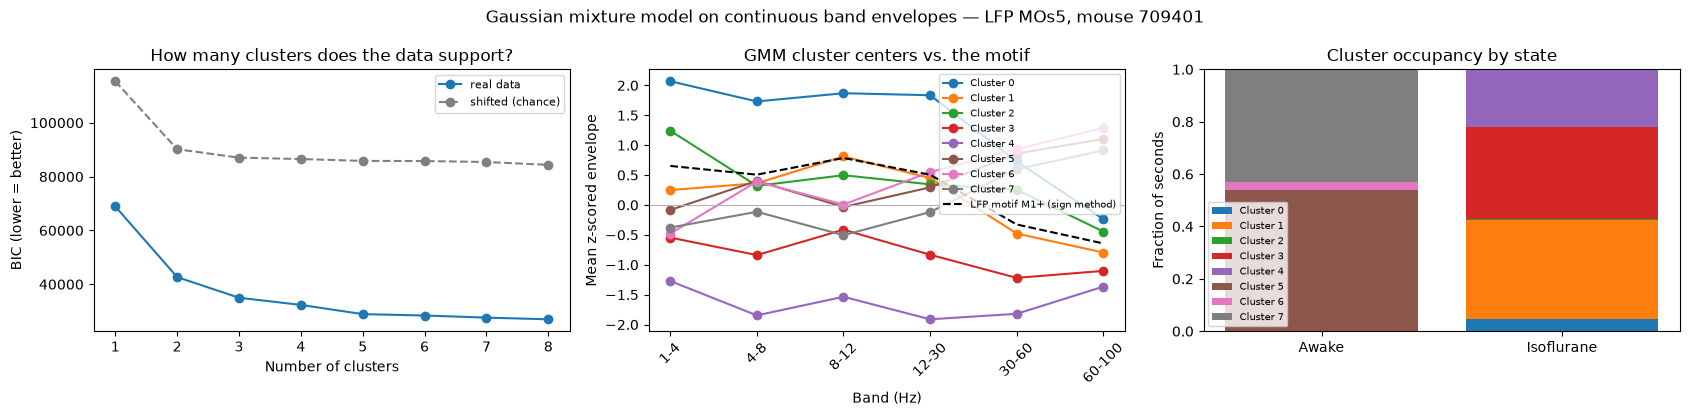

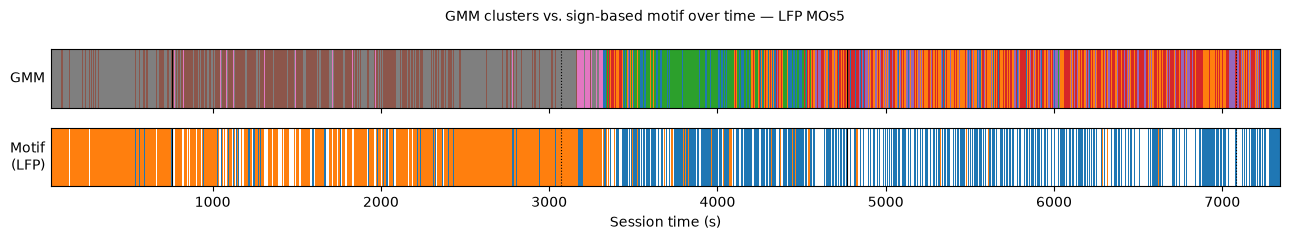

motif label   M1+   M1-  all-same-sign
GMM cluster                           
0            0.15  0.00           0.05
1            0.42  0.03           0.03
2            0.19  0.04           0.04
3            0.10  0.01           0.38
4            0.00  0.00           0.31
5            0.11  0.27           0.17
6            0.02  0.03           0.02
7            0.00  0.62           0.00


In [11]:
## ML EXTENSION
from sklearn.mixture import GaussianMixture
import pandas as pd
import matplotlib

SIGNAL = "LFP MOs5"            # or "EEG ch 13"
run = run_lfp if SIGNAL.startswith("LFP") else run_eeg[13]

X = run["env_1hz"]             # z-scored band envelopes, 1 per second, ALL seconds (none dropped)
state_of, t1 = run["state_of"], run["t_1hz"]
lfp_m1 = run_lfp["result"].motifs[:, 0]

def fit_gmm(data, ks=range(1, 9)):
    models = [GaussianMixture(k, covariance_type="full", n_init=5, random_state=0).fit(data) for k in ks]
    bics = np.array([m.bic(data) for m in models])
    return models[int(np.argmin(bics))], list(ks), bics

def shift_bands(data, step=20):
    """Same idea as the motif null: shift band b by 20*b seconds to break cross-band timing."""
    return np.column_stack([np.roll(data[:, b], step * b) for b in range(data.shape[1])])

gmm, ks, bic_real = fit_gmm(X)
gmm_null, _, bic_null = fit_gmm(shift_bands(X))

# Order clusters from "slow-dominant" to "fast-dominant" so the plot is readable
centers = gmm.means_
order = np.argsort(centers[:, :4].mean(1) - centers[:, 4:].mean(1))[::-1]
remap = {old: new for new, old in enumerate(order)}
labels = np.array([remap[l] for l in gmm.predict(X)])
centers = centers[order]
confidence = gmm.predict_proba(X).max(axis=1)
K = len(centers)

print(f"{SIGNAL}: BIC chose {K} clusters on real data, {gmm_null.n_components} on shifted (chance) data")
print(f"Median assignment confidence: {np.median(confidence):.0%} "
      f"(seconds below 60% confidence: {np.mean(confidence < 0.6):.0%})\n")
for c in range(K):
    corr = np.corrcoef(centers[c], lfp_m1)[0, 1]
    kind = "ALL BANDS UP" if (centers[c] > 0).all() else "ALL BANDS DOWN" if (centers[c] < 0).all() else ""
    occ = {s: np.mean(labels[state_of == s] == c) for s in ["awake", "isoflurane"]}
    print(f"Cluster {c}: corr with LFP M1+ = {corr:+.2f} | awake {occ['awake']:.0%} | "
          f"iso {occ['isoflurane']:.0%}  {kind}")

# --- Figures ---
band_labels = [f"{lo:g}-{hi:g}" for lo, hi in DEFAULT_FREQ_BANDS]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

axes[0].plot(ks, bic_real, "-o", label="real data")
axes[0].plot(ks, bic_null, "--o", color="0.5", label="shifted (chance)")
axes[0].set(xlabel="Number of clusters", ylabel="BIC (lower = better)", title="How many clusters does the data support?")
axes[0].legend(fontsize=8)

for c in range(K):
    axes[1].plot(band_labels, centers[c], "-o", color=f"C{c}", label=f"Cluster {c}")
axes[1].plot(band_labels, lfp_m1, "k--", lw=1.5, label="LFP motif M1+ (sign method)")
axes[1].axhline(0, color="0.7", lw=0.8)
axes[1].set(xlabel="Band (Hz)", ylabel="Mean z-scored envelope", title="GMM cluster centers vs. the motif")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(fontsize=7)

bottom = np.zeros(2)
for c in range(K):
    vals = np.array([np.mean(labels[state_of == s] == c) for s in ["awake", "isoflurane"]])
    axes[2].bar(["Awake", "Isoflurane"], vals, bottom=bottom, color=f"C{c}", label=f"Cluster {c}")
    bottom += vals
axes[2].set(ylabel="Fraction of seconds", title="Cluster occupancy by state")
axes[2].legend(fontsize=7)

fig.suptitle(f"Gaussian mixture model on continuous band envelopes — {SIGNAL}, mouse 709401")
plt.tight_layout()
plt.savefig(f"results/709401_jahan/gmm_{SIGNAL.replace(' ', '_')}.png", dpi=150)
plt.show()

# Timeline: GMM clusters vs. the sign-based motif labels
fig, axes = plt.subplots(2, 1, figsize=(13, 2.4), sharex=True)
axes[0].imshow(labels[None, :], aspect="auto", cmap=matplotlib.colors.ListedColormap([f"C{c}" for c in range(K)]),
               vmin=-0.5, vmax=K - 0.5, extent=[t1[0], t1[-1], 0, 1], interpolation="none")
axes[0].set_yticks([]); axes[0].set_ylabel("GMM", rotation=0, ha="right", va="center")
poles = run_lfp["pole_of"]
pole_rgb = np.ones((1, len(poles), 3))
pole_rgb[0, poles == 0] = matplotlib.colors.to_rgb("C0")
pole_rgb[0, poles == 1] = matplotlib.colors.to_rgb("C1")
axes[1].imshow(pole_rgb, aspect="auto", extent=[run_lfp["t_1hz"][0], run_lfp["t_1hz"][-1], 0, 1], interpolation="none")
axes[1].set_yticks([]); axes[1].set_ylabel("Motif\n(LFP)", rotation=0, ha="right", va="center")
for ax in axes:
    for _, a, b in STATES:
        ax.axvline(a, color="k", lw=0.8); ax.axvline(b, color="k", lw=0.8, ls=":")
axes[-1].set_xlabel("Session time (s)")
fig.suptitle(f"GMM clusters vs. sign-based motif over time — {SIGNAL}", fontsize=10)
plt.tight_layout()
plt.show()

# How GMM clusters line up with the motif labels (including the discarded all-same-sign seconds)
if SIGNAL.startswith("LFP"):
    pole_names = np.where(poles == 0, "M1+", np.where(poles == 1, "M1-", "all-same-sign"))
    print(pd.crosstab(pd.Series(labels, name="GMM cluster"), pd.Series(pole_names, name="motif label"),
                      normalize="columns").round(2))

Cluster 3 (35% of isoflurane): all bands moderately below average.

Cluster 4 (22% of isoflurane): all bands far below average (z ≈ −1.5 to −1.9), consistent with deep suppression.

The GMM found the same slow-vs-fast pattern as the motif (r = ±0.97). It also assigned most discarded all-same-sign seconds to their own clusters (69% to clusters 3 and 4): broadband suppression states making up 57% of isoflurane, plus a small cluster of mostly broadband high activity, possibly bursts.